# From PAL data to wind speed

**ArgoPAL** turns the passive acoustic (PAL) measurements of BGC-Argo floats
into surface wind speed, starting from a float's WMO number and using only
data from the Argo GDAC.

This notebook goes through the full pipeline, from the acoustic spectra to
depth-corrected and calibrated wind speed, on float **7902280** (Ligurian
Sea, 2026).  To get only the acoustic data (every band, with the float's
CTD/BGC data, no further processing), see
[Getting the PAL data](pal_data_tutorial.ipynb).

1. one-call processing
2. what the float measured
3. processing options
4. the pipeline step by step
5. figures to follow each step
6. wind speed from published models
7. calibration against reference buoys, with uncertainty
8. ship noise with AIS (optional)
9. export

Installation:

```
pip install git+https://github.com/louisedelaigue/ArgoPAL.git
pip install "argopal[ais] @ git+https://github.com/louisedelaigue/ArgoPAL.git"  # raw NMEA AIS
```

In [1]:
import warnings

import argopal

warnings.simplefilter("ignore")  # ArgoPAL warnings are discussed in the text
argopal.hello()


A  Wind from passive acoustics
r  on BGC-Argo floats
g
o  Version 0.1.0b2
P
A
L



## 1. One call

`process_float` downloads the float's files from the GDAC (acoustic spectra
from the *aux* folder; CTD, oxygen, pH and positions from the core files),
then runs every processing step.  Defaults: delayed-mode data only, 8 kHz
band, β per profile, despiking over ±1.5 h at the 95th percentile.

In [2]:
result = argopal.process_float(7902280, verbose=False)
list(result)

['park',
 'pal_raw',
 'park_samples',
 'profiles',
 'ts_profiles',
 'beta',
 'positions',
 'meta',
 'files']

`result["park"]` holds one row per acoustic measurement: band level, depth
correction β, depth-corrected spectral level, position, park T/S/O₂ and wind
speed from each published model.

In [3]:
park = result["park"]
cols = ["cycle", "datetime", "latitude", "longitude", "pressure",
        "f_8000Hz", "beta_8000Hz", "spl_8000Hz", "U_nystuen2015"]
park[cols].dropna().head()

,cycle,datetime,latitude,longitude,pressure,f_8000Hz,beta_8000Hz,spl_8000Hz,U_nystuen2015
0,1,2026-01-12 04:48:59.446877696,43.752416,9.103861,974.700012,47.625000,0.951016,48.576016,10.070965
1,1,2026-01-12 04:59:00.433076736,43.752426,9.103781,986.700012,47.666667,0.961430,48.628097,10.124104
2,1,2026-01-12 05:09:01.419275776,43.752437,9.103701,993.799988,47.750000,0.967585,48.717585,10.215942
3,1,2026-01-12 05:19:02.405474304,43.752448,9.103621,996.000000,47.727273,0.969493,48.696766,10.194515
4,1,2026-01-12 05:29:03.391673856,43.752458,9.103541,995.900024,47.708333,0.969406,48.677740,10.174967


In delayed mode, every value comes from delayed-mode Argo data only, with no
fallback.  For a young float, most profiles are not in delayed mode yet, so
the depth correction (and everything after it) is available only for the
first months:

In [4]:
print(f"{park['spl_8000Hz'].notna().mean():.0%} of measurements have a "
      f"depth-corrected level in {park.attrs['park']['mode']!r} mode")
cycles = result["ts_profiles"].attrs["cycles"]
print(f"profiles used for β: cycles {cycles[0]} to {cycles[-1]}")

63% of measurements have a depth-corrected level in 'delayed' mode
profiles used for β: cycles 1 to 37


## 2. What the float measured

The variables available in each file, with how many values are in delayed
(D), adjusted (A) and real-time (R) mode:

In [5]:
argopal.available_variables("argopal_data/7902280")

,file,variable,counted_per,n,n_D,n_A,n_R,n_adjusted_values
0,7902280_Rtraj.nc,TEMP,measurement,25443,0,0,25443,0
1,7902280_Rtraj.nc,PRES,measurement,124716,0,6148,118568,6148
2,7902280_Rtraj.nc,PSAL,measurement,25442,0,12911,12531,12911
3,7902280_Rtraj.nc,C1PHASE_DOXY,measurement,42769,0,0,42769,0
4,7902280_Rtraj.nc,C2PHASE_DOXY,measurement,42769,0,0,42769,0
5,7902280_Rtraj.nc,TEMP_DOXY,measurement,42769,0,0,42769,0
6,7902280_Rtraj.nc,DOXY,measurement,41869,0,41792,77,41792
7,7902280_Rtraj.nc,VRS_PH,measurement,20653,0,0,20653,0
8,7902280_Rtraj.nc,PH_IN_SITU_FREE,measurement,20653,0,0,20653,0
9,7902280_Rtraj.nc,PH_IN_SITU_TOTAL,measurement,20653,0,0,20653,0


The hydrophone and its configuration come from the `meta_aux` file.  This
float normalises band levels by bandwidth on board, so they are already
spectral levels:

In [6]:
meta = result["meta"]
print(meta["sensor_model"], meta["sensor_serial_no"])
print("band normalisation on board:", meta["band_normalization"])
print("spectra by band layout:", result["pal_raw"].attrs["band_layout_counts"])

HTI_96_MIN H31-01246
band normalisation on board: True
spectra by band layout: {'23': 306, '9': 71830, 'other': 0}


Almost all spectra are 9-band spectra (63, 125, 400 Hz, 1, 2, 5, 8, 12.5,
20 kHz), stored in the 23-band array with the other bands empty:

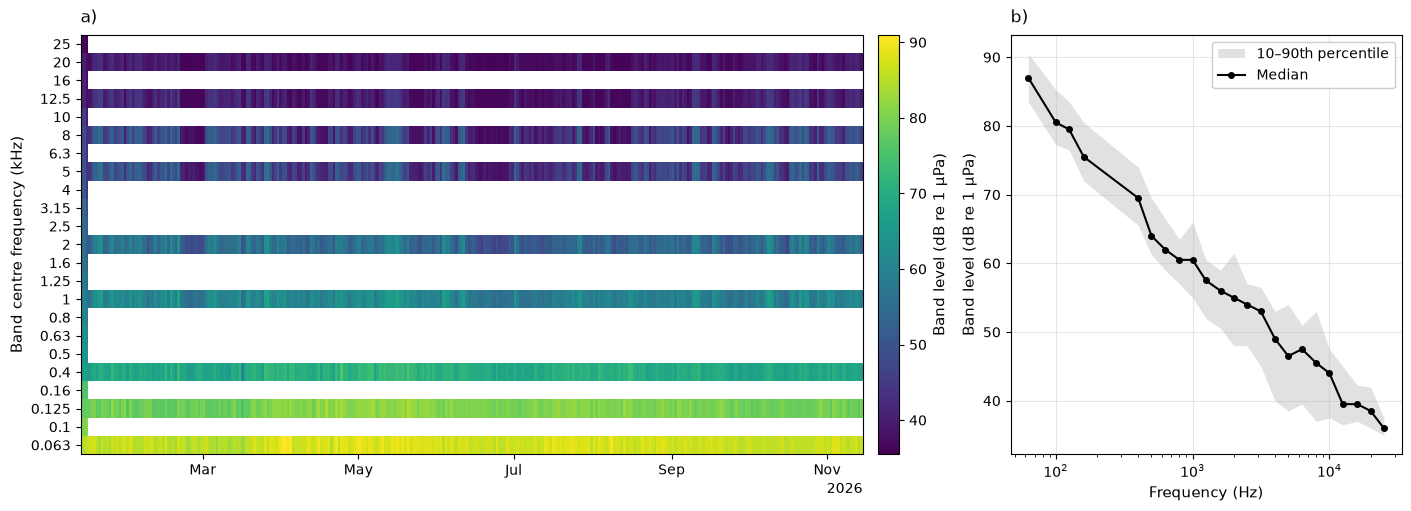

In [7]:
fig, axes = argopal.plot_pal_spectra(result["pal_raw"])

## 3. Options

- `mode`: `"delayed"` (default), `"adjusted"` or `"raw"`; one source each,
  no fallback.
- `bands`: frequency bands to process; default 8 kHz.  Bands without data
  are dropped with a warning (here 3.15 kHz, absent from 9-band spectra).
- `despike_window`, `despike_percentile`; `beta_method="mean"` for one β
  from the deployment-mean profile.

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    raw = argopal.process_float(7902280, mode="raw", bands=(3150, 8000), verbose=False)
print([str(w.message)[:110] for w in caught if "band" in str(w.message)])
print("bands processed:", raw["park"].attrs["bands_hz"])
print(f"depth-corrected in raw mode: {raw['park']['spl_8000Hz'].notna().mean():.0%}")

['WMO 7902280: the 3150 Hz band is not used: it has values in only 0.4% of spectra. Bands with data: 63, 125, 40']
bands processed: [8000]
depth-corrected in raw mode: 100%


## 4. Step by step

Each step of `process_float` is a function of its own; tables can be
inspected, changed or exported between steps.

In [9]:
files = argopal.download_aux(7902280, verbose=False) | argopal.download_core(7902280, verbose=False)

meta = argopal.read_pal_meta(files["7902280_meta_aux.nc"])
pal = argopal.read_pal(files["7902280_Rtraj_aux.nc"], meta=meta)           # spectra
pal = argopal.select_bands(pal, bands=8000)                                # 8 kHz
pal = argopal.clean_pal(pal)                                               # park drift, QC, despike

park_samples = argopal.read_park(files["7902280_Rtraj.nc"], mode="raw")    # park CTD/BGC
pal = argopal.attach_park(pal, park_samples)                               # linear in time
pal = argopal.attach_positions(pal, argopal.read_positions(files["7902280_Rtraj.nc"]))

profiles = argopal.read_profiles(files["7902280_Sprof.nc"], mode="raw")
ts = argopal.gridded_profiles(profiles, max_pressure=pal["pressure"].max() + 10)
beta = argopal.compute_profile_betas(ts, pal.attrs["bands_hz"])           # β per profile
pal = argopal.depth_correct(pal, beta)                                     # β in time and depth
pal = argopal.spectral_level(pal)                                          # dB re 1 µPa² Hz⁻¹
pal = argopal.wind_literature(pal)                                         # published models

pal[["datetime", "pressure", "f_8000Hz", "beta_8000Hz", "spl_8000Hz",
     "U_vagle1990", "U_nystuen2015", "U_pensieri2015"]].dropna().head()

,datetime,pressure,f_8000Hz,beta_8000Hz,spl_8000Hz,U_vagle1990,U_nystuen2015,U_pensieri2015
0,2026-01-12 04:48:59.446877696,974.700012,47.625000,0.951016,48.576016,6.672732,10.070965,8.456901
1,2026-01-12 04:59:00.433076736,986.700012,47.666667,0.961430,48.628097,6.702976,10.124104,8.511465
2,2026-01-12 05:09:01.419275776,993.799988,47.750000,0.967585,48.717585,6.755340,10.215942,8.605786
3,2026-01-12 05:19:02.405474304,996.000000,47.727273,0.969493,48.696766,6.743112,10.194515,8.583779
4,2026-01-12 05:29:03.391673856,995.900024,47.708333,0.969406,48.677740,6.731961,10.174967,8.563700


## 5. Figures

One figure per step, in the style of Delaigue et al. (2026).
`argopal.plot_all(result, save_dir="figures")` saves all of them at 300 dpi;
here a few, on the raw-mode run.

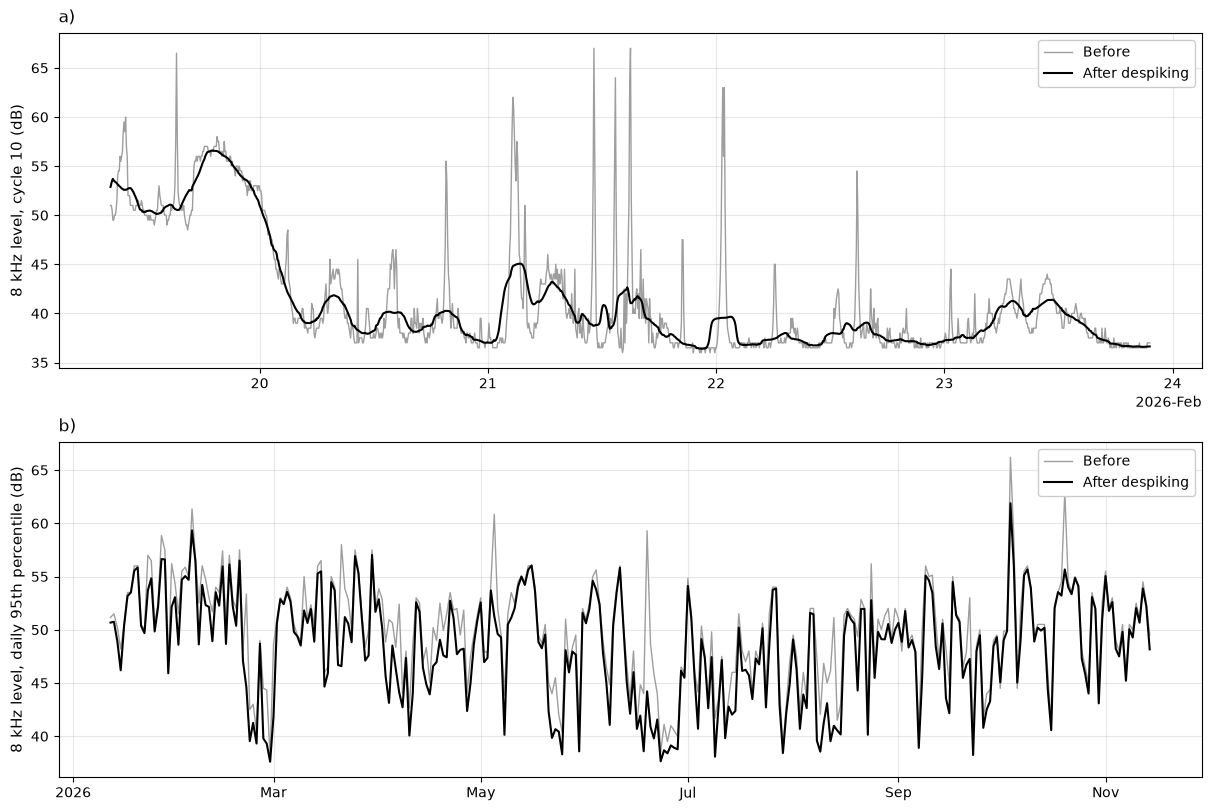

In [10]:
fig, axes = argopal.plot_despike(raw["pal_raw"], raw["park"], cycle=10)

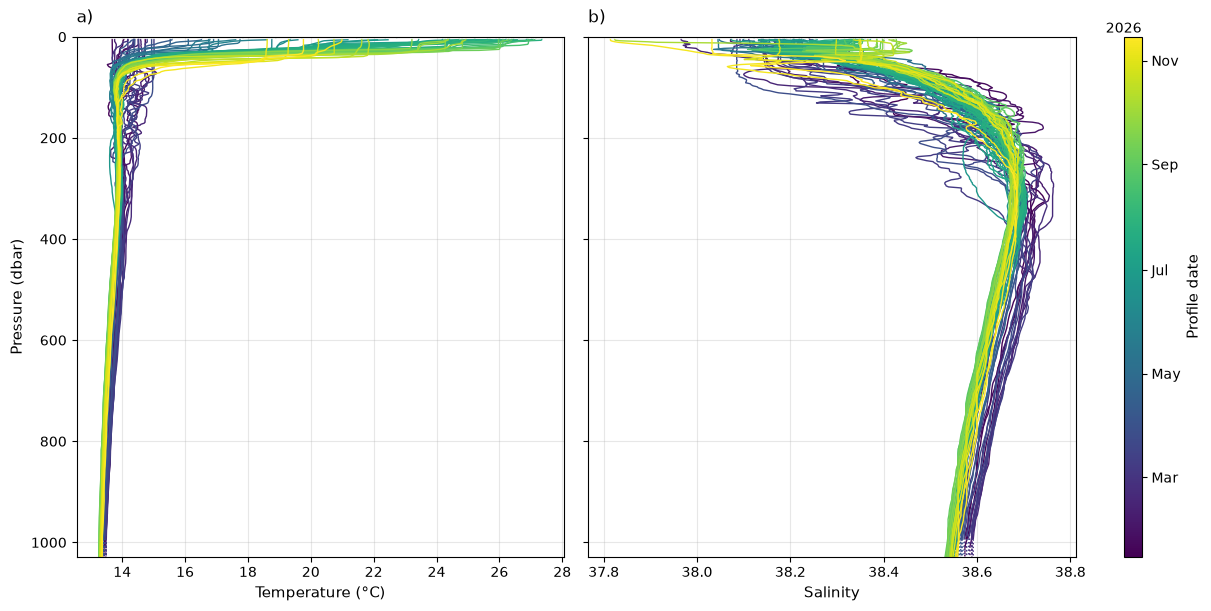

In [11]:
fig, axes = argopal.plot_profiles(raw["ts_profiles"])

β follows the season: the summer thermocline changes the sound-speed
profile and so the propagation of surface noise down to the hydrophone.

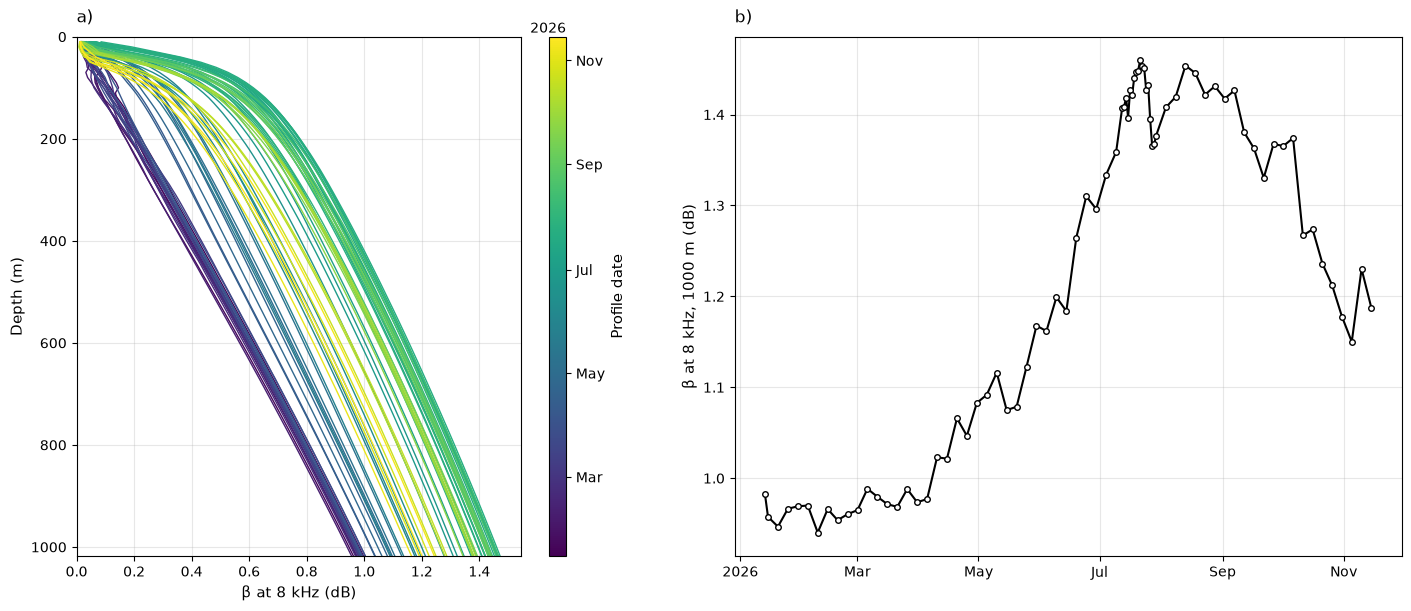

In [12]:
fig, axes = argopal.plot_beta(raw["beta"])

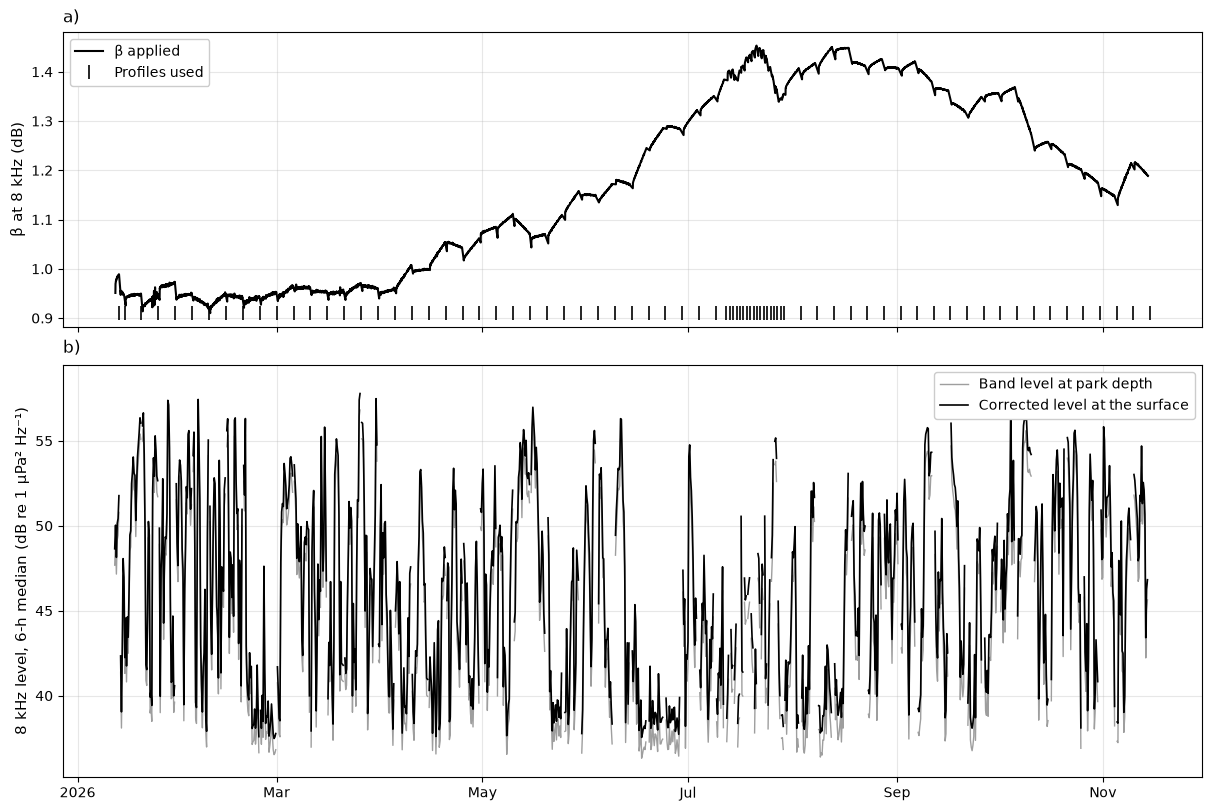

In [13]:
fig, axes = argopal.plot_depth_correction(raw["park"], beta=raw["beta"])

## 6. Wind speed from published models

Vagle et al. (1990), Nystuen et al. (2015) and Pensieri et al. (2015), all at
8 kHz, with their published coefficients (`U_<model>` columns).  Each is also
a function: e.g. `argopal.wind_nystuen2015(spl)`.

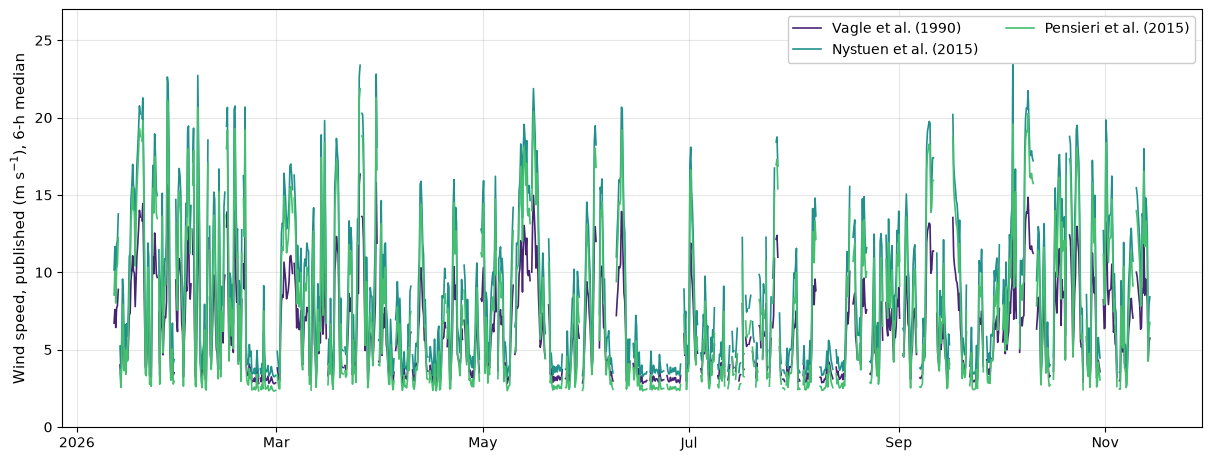

In [14]:
fig, axes = argopal.plot_wind(raw["park"])

## 7. Calibration against reference buoys

Published coefficients are not tuned to floats.  With a reference wind, the
models are refitted (nonlinear least squares, measurements within 40 km of
a reference), and each refitted wind gets an uncertainty.

ArgoPAL does not download reference winds: one table holds them all, here
three Météo-France buoys (DYFAMED, LION, PACA), January–June 2026.  Columns
`reference_name`, `datetime`, `latitude`, `longitude`, `wind_speed`, and
optionally `wind_speed_sigma`, the error of each value, and `height_m`, the
height of the wind measurement.

The wind models are calibrated against **10 m wind**, so the reference
must be 10 m wind too.  These buoys measure wind at about 3.5 m
(`height_m` = 3.5); ArgoPAL converts it to 10 m when reading the table
(`argopal.wind_to_10m`, a factor of about 1.10 here).  The float wind,
from models calibrated against 10 m wind, is then 10 m wind as well.

In [15]:
import pandas as pd

buoys = pd.read_csv("data/reference_winds_2026.csv")
buoys.groupby("reference_name")[["latitude", "longitude", "height_m"]].mean().round(2)

,latitude,longitude,height_m
reference_name,,,
DYFAMED,43.36,7.84,3.5
LION,42.10,4.68,3.5
PACA,42.45,6.84,3.5


Each measurement is matched to the closest buoy with a value within 1 h.

The float measures every 5 min and the buoys report hourly.  So for each
buoy value, the measurements from **30 min before to 30 min after** its
time are averaged first (`reference_window="1h"`, the default; any width
can be given, e.g. `"30min"` or `"3h"`).  The models are fitted and
assessed on these hourly points, then applied to every measurement.

`fit_max_distance_km` sets the radius used for fitting, skill and
uncertainty (40 km by default).

In [16]:
cal = argopal.process_float(
    7902280,
    mode="raw",
    reference={"buoys": "data/reference_winds_2026.csv"},
    fit_max_distance_km=40,
    verbose=False,
)
cal["park"].attrs["references"]["buoys"]["references"]

{'DYFAMED': 14977, 'LION': 48, 'PACA': 27155}

The float passed within 40 km of DYFAMED in February 2026 (cycles 9–12)
and of PACA in April 2026 (cycles 17–22); while the LION record lasts
(to June), the float is more than 100 km from it.  The refit pools the
measurements near both buoys.

In [17]:
p = cal["park"]
p.groupby("buoys_reference_name")["buoys_distance_km"].describe()[
    ["count", "min", "50%", "max"]
].round(1)

,count,min,50%,max
buoys_reference_name,,,,
DYFAMED,14977.0,23.3,67.1,110.6
LION,48.0,113.7,123.9,133.2
PACA,27155.0,14.0,57.8,135.9


On a map: the trajectory, the measurements within 40 km of the buoy they
were matched to (black, those used for the refit), and the buoys used,
each with a 40 km circle (LION, never used, is not shown).  With
`annotate=True`, the figure also notes buoys reported at several
positions: PACA appears at two positions about 25 km apart in the
Météo-France file, and is shown at the more frequent one.

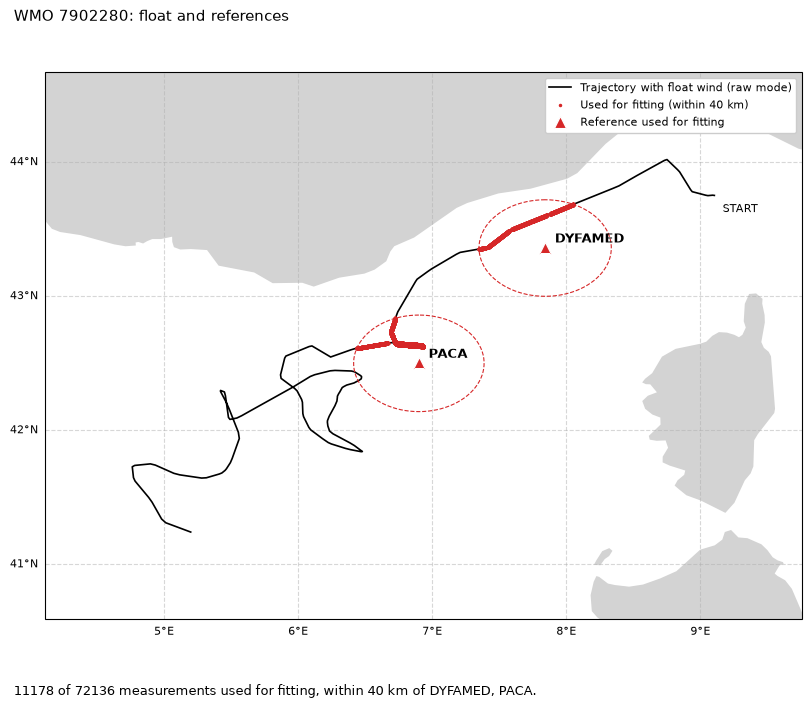

In [18]:
fig, ax = argopal.plot_reference_map(cal["park"], annotate=True)

In [19]:
cal["wind_fits"][["model", "reference_name", "n", "n_applied",
                  "rmse_published", "rmse_fitted", "r2_fitted",
                  "bias_published"]].round(2)

,model,reference_name,n,n_applied,rmse_published,rmse_fitted,r2_fitted,bias_published
0,vagle1990,DYFAMED,334,15051,3.14,2.39,0.78,-1.18
1,vagle1990,PACA,596,37752,1.99,1.91,0.67,-0.36
2,nystuen2015,DYFAMED,334,15051,2.48,2.38,0.78,0.64
3,nystuen2015,PACA,596,37752,2.89,1.90,0.67,1.83
4,pensieri2015,DYFAMED,334,15051,2.51,2.39,0.78,-0.69
5,pensieri2015,PACA,596,37752,2.23,1.92,0.67,0.35


**One calibration per buoy.**  Each buoy's coefficients are fitted on the
float data near it, and used there (`n` points).  Every other measurement
uses the coefficients of the closest buoy (`n_applied` in all), and
`buoys_calibration` says whose.  A buoy needs float data in at least 4
cycles to get coefficients; the measurements closest to a buoy without
any get no refitted wind.  Here LION, never within 40 km, has none: the
measurements closest to it (`buoys_closest`) have no refitted wind (grey
along the top of the figure below).  `calibration="pooled"` would fit one set
of coefficients to both buoys together.

The whole record, two months per row: the refitted wind with ±1σ, the
periods used for each buoy's refit shaded in its colour, and along the
top whose coefficients apply:

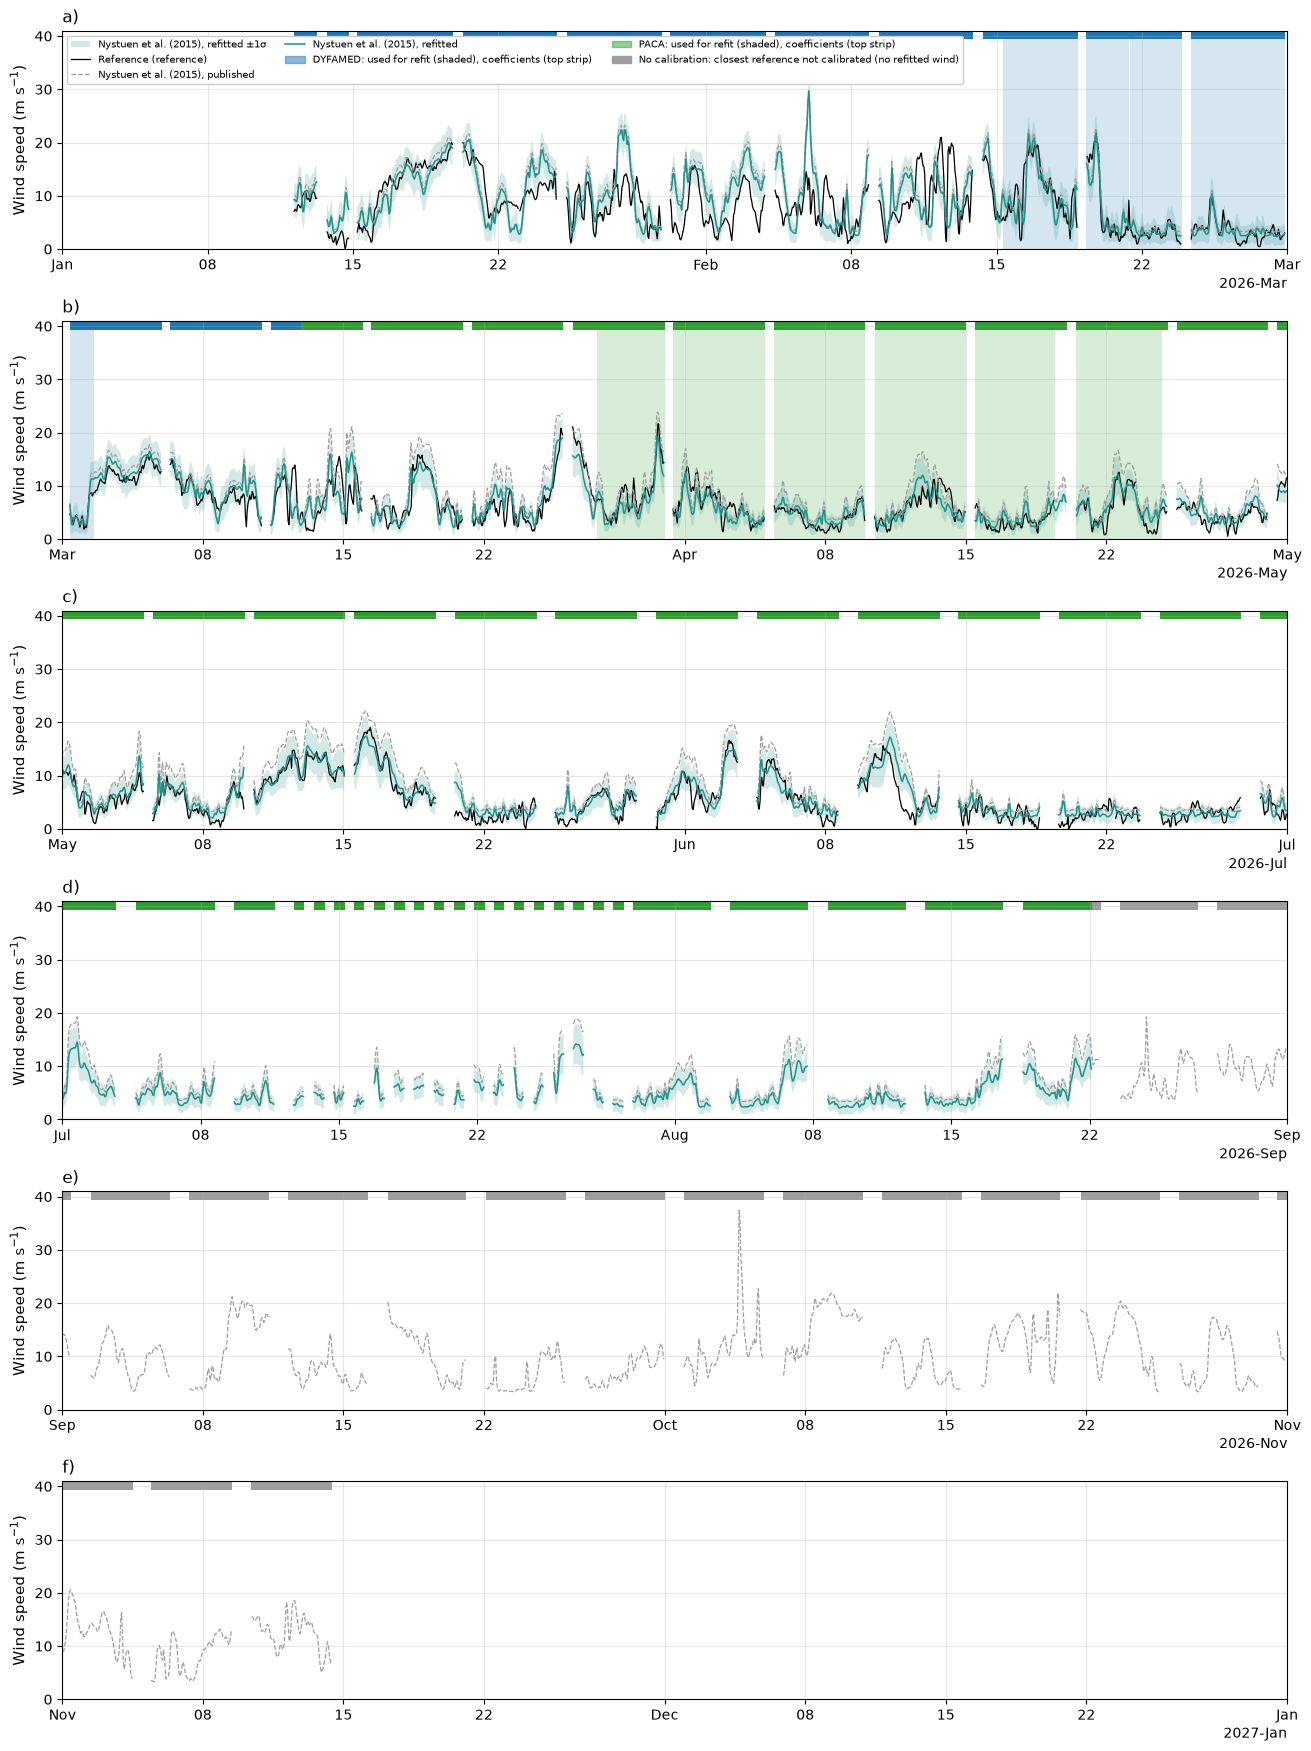

In [20]:
fig, axes = argopal.plot_wind_timeline(cal["park"])

Skill of every wind estimate against the buoys within 40 km, all together
and per buoy:

In [21]:
cal["wind_skill"].round(2)

,wind,reference,reference_name,n,bias,rmse,r2,pearson_r2,slope,intercept
0,U_vagle1990,buoys,all,930,-0.66,2.46,0.64,0.71,0.53,2.09
1,U_vagle1990_fit,buoys,all,930,0.01,2.09,0.74,0.74,0.73,1.54
2,U_nystuen2015,buoys,all,930,1.40,2.75,0.55,0.70,0.87,2.17
3,U_nystuen2015_fit,buoys,all,930,-0.00,2.09,0.74,0.74,0.74,1.52
4,U_pensieri2015,buoys,all,930,-0.02,2.33,0.67,0.70,0.84,0.89
5,U_pensieri2015_fit,buoys,all,930,-0.00,2.10,0.73,0.73,0.73,1.54
6,U_vagle1990,buoys,DYFAMED,334,-1.18,3.14,0.63,0.78,0.50,1.84
7,U_vagle1990_fit,buoys,DYFAMED,334,0.00,2.39,0.78,0.78,0.78,1.31
8,U_nystuen2015,buoys,DYFAMED,334,0.64,2.48,0.77,0.78,0.82,1.74
9,U_nystuen2015_fit,buoys,DYFAMED,334,-0.00,2.38,0.78,0.78,0.78,1.31


Uncertainty, per measurement and per refitted model.  By default, one
term: `U_<model>_fit_sigma_cv`, the empirical error, cross-validated by
leaving one cycle out and binned by wind speed; `U_<model>_fit_sigma` is
then the same.  Two more terms are optional
(`uncertainty=["cv", "coef", "ref"]` or `"all"` in `process_float`,
`components=` in `wind_uncertainty`):

- `_sigma_coef`: coefficient uncertainty, bootstrap over cycles
  (unreliable with fewer than about 10 cycles);
- `_sigma_ref`: the buoys' own error (`reference_sigma`, or the table's
  `wind_speed_sigma`), removed from σ_cv, which contains it;

combined as √(max(σ_cv² − σ_ref², 0) + σ_coef²).

The empirical error by wind-speed bin:

In [22]:
cal["wind_uncertainty"].round(2)

,model,reference_name,wind,sigma_cv,n,lo,hi
0,vagle1990,DYFAMED,3.21,1.48,177,2.0,4.0
1,vagle1990,DYFAMED,4.80,3.62,54,4.0,6.0
2,vagle1990,DYFAMED,8.04,3.10,43,6.0,10.0
3,vagle1990,DYFAMED,14.72,3.16,60,10.0,24.0
4,vagle1990,PACA,3.36,1.44,208,2.0,4.0
5,vagle1990,PACA,4.90,2.22,170,4.0,6.0
6,vagle1990,PACA,6.89,2.14,122,6.0,8.0
7,vagle1990,PACA,8.90,2.00,44,8.0,10.0
8,vagle1990,PACA,11.59,3.32,52,10.0,16.0
9,nystuen2015,DYFAMED,2.96,1.82,163,2.0,4.0


The cross-validated error already includes the effect of fitting the
coefficients on a few cycles.  The refit should still not be trusted far
outside the winds seen near the buoys.

In [23]:
cols = [c for c in cal["park"] if c.startswith("U_nystuen2015_fit_sigma")]
cal["park"][cols].quantile([0.5, 0.9]).round(2)

,U_nystuen2015_fit_sigma_cv,U_nystuen2015_fit_sigma
0.5,2.14,2.14
0.9,3.28,3.28


Refitted wind against the buoys, coloured by distance (as in Fig. 5 of
Delaigue et al. 2026).  By default the figure shows every measurement within
80 km, so its statistics include measurements further away than those used
for fitting:

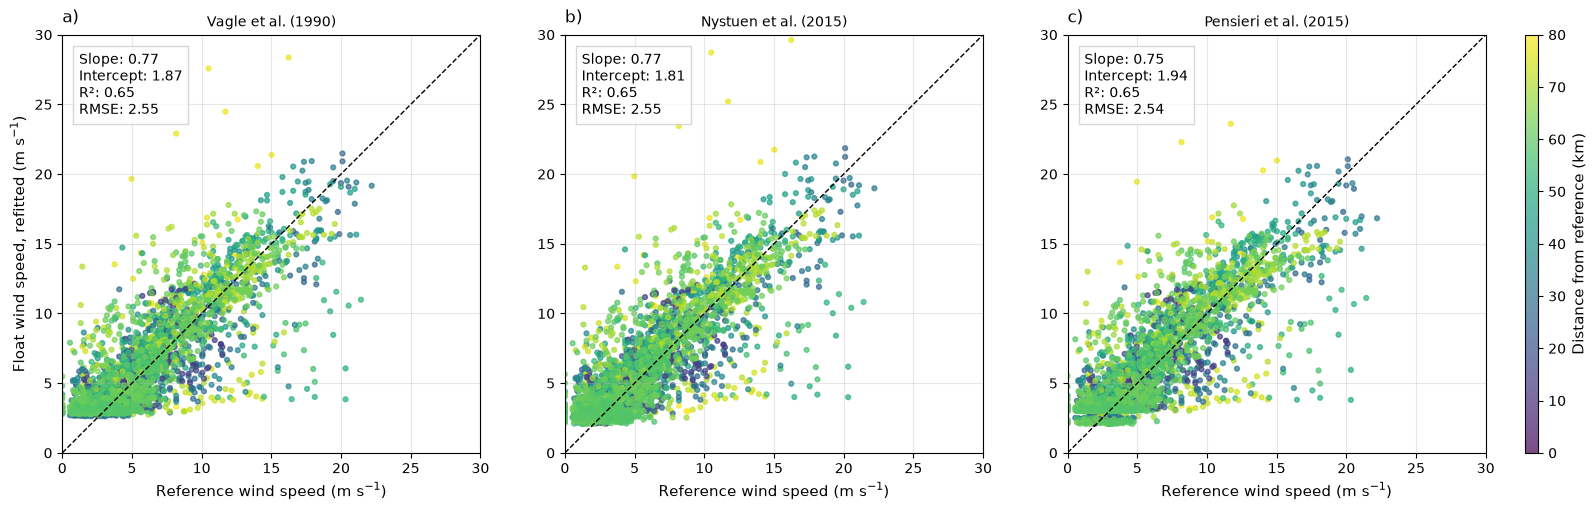

In [24]:
fig, axes = argopal.plot_wind_fit(cal["park"])

Restricted to the 40 km used for fitting, the statistics match `wind_fits`:

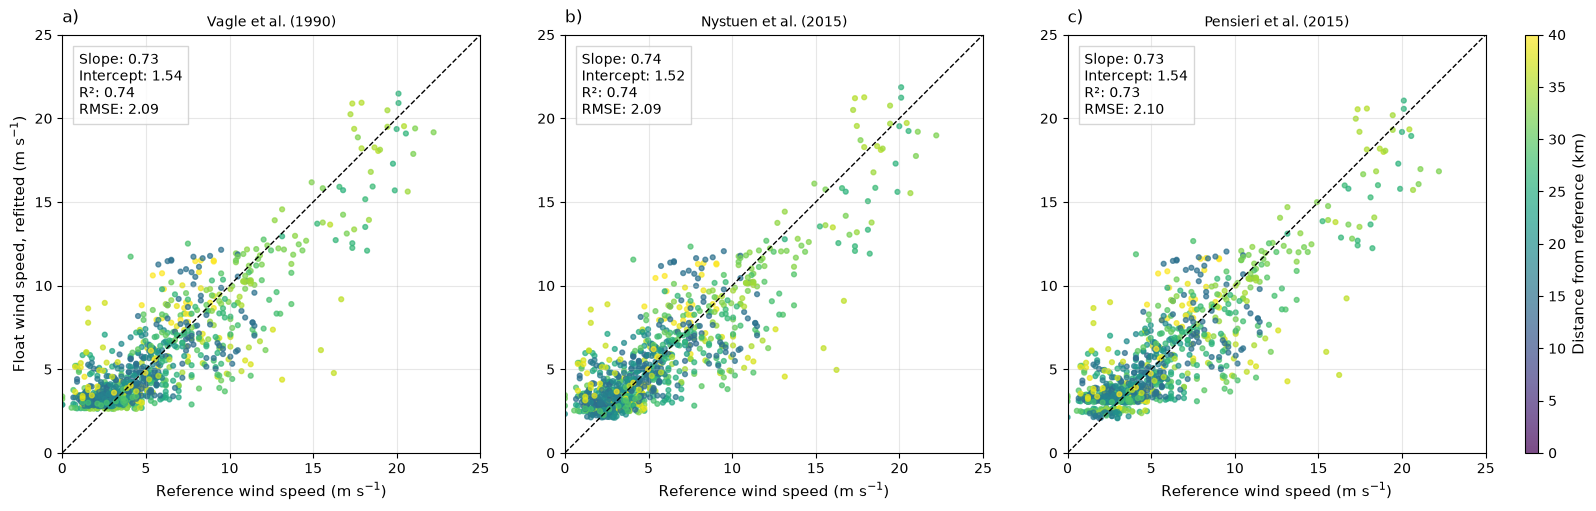

In [25]:
fig, axes = argopal.plot_wind_fit(cal["park"], max_distance_km=40)

The same points through time: the buoy wind, and Nystuen et al. (2015)
with its published and refitted coefficients.  Each point belongs to the
buoy the float was matched to, the closest one with a value within the
hour, so one row per buoy:

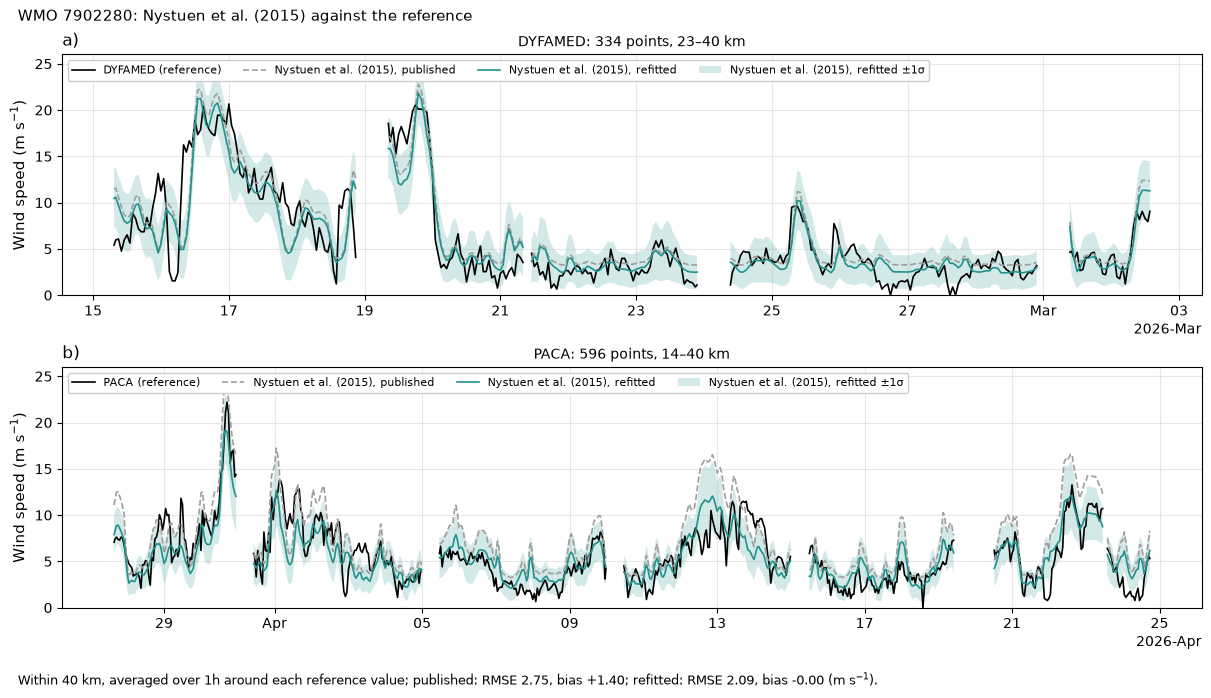

In [26]:
fig, axes = argopal.plot_reference_timeseries(cal["park"], annotate=True)

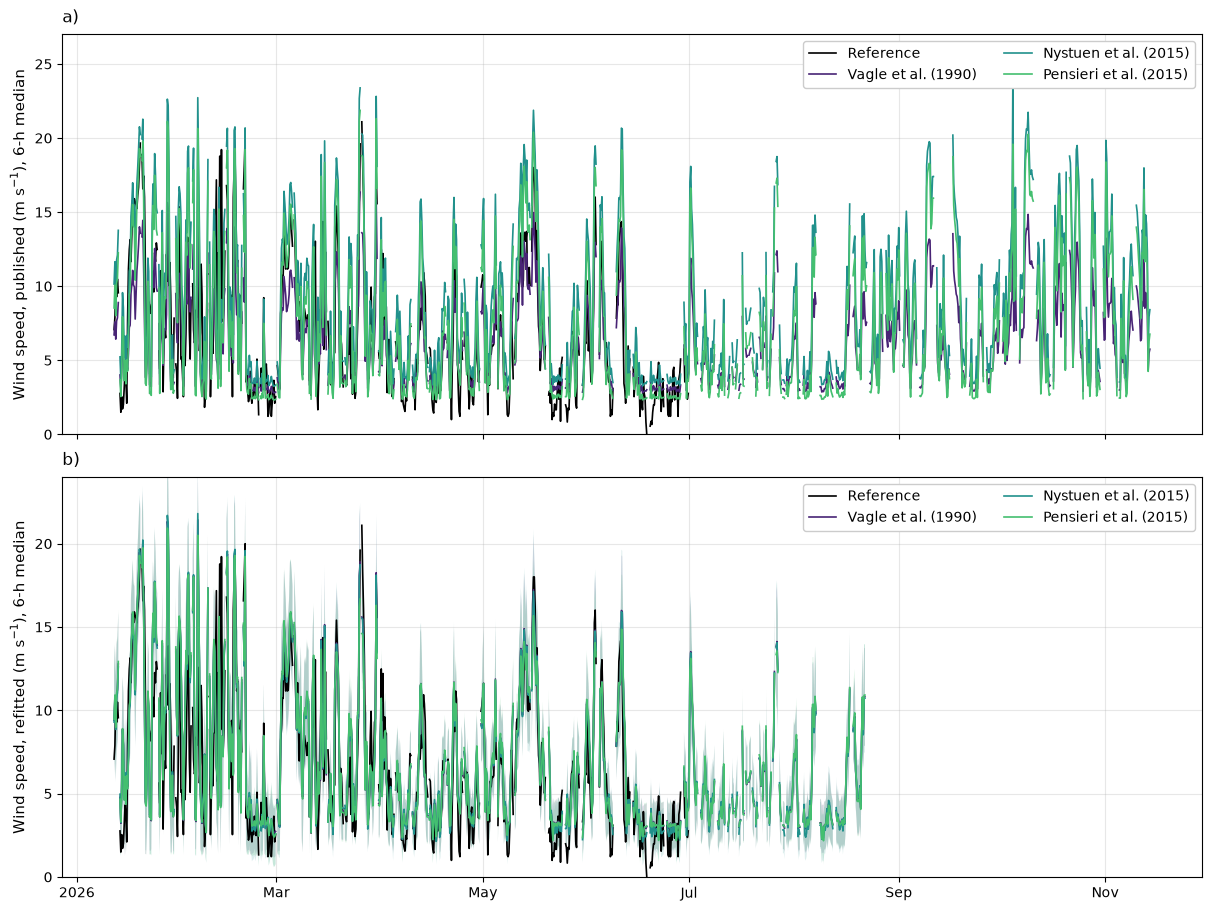

In [27]:
fig, axes = argopal.plot_wind(cal["park"])

### More with references

The same steps can be run one by one on any processed table, here the
raw-mode `park` table from section 3, which has no reference yet.

**Radius.** `fit_max_distance_km` in `process_float`, or `max_distance_km`
in `fit_wind_models`, `wind_skill` and `wind_uncertainty`, sets how close a
measurement must be to its reference to be used; `None` uses all.  To
compare settings with one number each, these examples fit one set of
coefficients for both buoys (`calibration="pooled"`).

In [28]:
park = argopal.collocate_reference(raw["park"], buoys, name="buoys")
for radius in (10, 25, 40, 80):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _, fits = argopal.fit_wind_models(
            park, max_distance_km=radius, calibration="pooled"
        )
    row = fits.set_index("model").loc["nystuen2015"]
    print(f"{radius:>3} km: n = {row['n']:>6}, RMSE = {row['rmse_fitted']:.2f}, "
          f"R² = {row['r2_fitted']:.2f}")

 10 km: n =      0, RMSE = nan, R² = nan
 25 km: n =    437, RMSE = 1.51, R² = 0.56
 40 km: n =    930, RMSE = 2.20, R² = 0.71
 80 km: n =   2973, RMSE = 2.53, R² = 0.65


No measurement is within 10 km of a buoy, so nothing is refitted there
(the model keeps its row, with n = 0).  The RMSE grows with the radius, as
buoy winds further from the float represent its wind less well; R² also
depends on the range of winds covered, which is narrower within 25 km.

**Which reference each measurement used.**  The closest buoy with a value
within `max_time` (1 h by default), with its distance and time difference:

In [29]:
park[["datetime", "U_buoys", "buoys_reference_name", "buoys_distance_km",
      "buoys_dt_min"]].dropna().iloc[::5000]

,datetime,U_buoys,buoys_reference_name,buoys_distance_km,buoys_dt_min
0,2026-01-12 04:48:59.446877696,7.068917,DYFAMED,110.617682,11.000000
5012,2026-02-02 02:12:53.042608128,5.301687,DYFAMED,91.537823,-12.900000
10012,2026-02-21 09:48:55.678536704,9.167501,PACA,135.752345,-48.933333
15012,2026-03-12 17:19:36.366290944,7.510724,DYFAMED,74.795292,-19.616667
20012,2026-04-01 00:19:26.565256192,11.597441,PACA,29.308264,-19.450000
25172,2026-04-20 21:59:58.792952832,6.848013,PACA,26.492344,0.016667
30184,2026-05-09 20:21:48.502593536,6.406206,PACA,57.303508,-21.816667
35184,2026-05-31 02:33:37.635201536,5.080784,PACA,57.879600,26.366667
40184,2026-06-21 09:11:28.697395712,2.319488,PACA,61.763124,-11.483333


**Averaging window.**  `window` in `fit_wind_models` (or
`reference_window` in `process_float`) sets how much float data is
averaged around each buoy value: `"1h"` (default) is 30 min before to
30 min after.  `"nearest"` averages the measurements whose nearest buoy
value it is, and `average=False` uses every measurement on its own.

In [30]:
for window in ("20min", "1h", "2h"):
    _, fits = argopal.fit_wind_models(
        park, max_distance_km=40, window=window, calibration="pooled"
    )
    row = fits.set_index("model").loc["nystuen2015"]
    print(f"{window:>6}: {row['n']} buoy values, "
          f"{row['n_measurements'] / row['n']:.1f} measurements each, "
          f"RMSE = {row['rmse_fitted']:.2f}")
_, fits = argopal.fit_wind_models(
    park, max_distance_km=40, average=False, calibration="pooled"
)
row = fits.set_index("model").loc["nystuen2015"]
print(f"  none: {row['n']} measurements, RMSE = {row['rmse_fitted']:.2f}")

 20min: 921 buoy values, 4.0 measurements each, RMSE = 2.20


    1h: 930 buoy values, 11.8 measurements each, RMSE = 2.20
    2h: 930 buoy values, 23.6 measurements each, RMSE = 2.18
  none: 11178 measurements, RMSE = 2.20


**Collocation time limit and distance.**  `max_time` sets how far in
time the nearest buoy value may be;
`max_distance_km` in `collocate_reference` blanks reference values further
away than that (by default they are kept, so that fitting and figures can
choose).

In [31]:
strict = argopal.collocate_reference(
    raw["park"], buoys, name="buoys", max_time="30min", max_distance_km=40
)
print(f"{strict['U_buoys'].notna().sum()} measurements with a buoy wind "
      f"within 30 min and 40 km, of {len(strict)}")

10982 measurements with a buoy wind within 30 min and 40 km, of 72136


**Skill per reference.**  `by_reference=True` adds one set of rows per
buoy to the skill table:

In [32]:
fitted, _ = argopal.fit_wind_models(park, max_distance_km=40)
skill = argopal.wind_skill(fitted, max_distance_km=40, by_reference=True)
skill[skill["wind"] == "U_nystuen2015_fit"].round(2)

,wind,reference,reference_name,n,bias,rmse,r2,pearson_r2,slope,intercept
3,U_nystuen2015_fit,buoys,all,930,-0.0,2.09,0.74,0.74,0.74,1.52
9,U_nystuen2015_fit,buoys,DYFAMED,334,-0.0,2.38,0.78,0.78,0.78,1.31
15,U_nystuen2015_fit,buoys,PACA,596,-0.0,1.90,0.67,0.67,0.67,1.84


**Error of each reference value.**  A `wind_speed_sigma` column in the
table is carried to each measurement (`<name>_sigma`) and used as σ_ref by
`wind_uncertainty` with `components=["cv", "ref"]` (or `"all"`), unless
`reference_sigma` is given.  The values below
are only for illustration: these buoys do not give an error per value.

In [33]:
illustrative = buoys.assign(
    wind_speed_sigma=buoys["reference_name"].map(
        {"DYFAMED": 0.5, "LION": 0.5, "PACA": 0.8}
    )
)
p = argopal.collocate_reference(raw["park"], illustrative, name="buoys")
p, _ = argopal.fit_wind_models(p, models=["nystuen2015"])
p, _ = argopal.wind_uncertainty(p, components=["cv", "ref"])
by_buoy = p.attrs["wind_uncertainty"]["models"]["nystuen2015"]
print("σ_ref from the table:",
      {buoy: round(v["sigma_ref"], 2) for buoy, v in by_buoy.items()})

σ_ref from the table: {'DYFAMED': 0.5, 'PACA': 0.8}


**Do the buoys agree?**  `reference_diagnostics` fits the model to each
buoy separately and to all together.  A buoy's own fit always looks
better on its own data; the cross-validated RMSE (each cycle predicted
by a fit without it) says whether it really is, and the transfer table
how one buoy's coefficients do on the other:

In [34]:
d = argopal.reference_diagnostics(cal["park"])
d["fits"][["reference", "n", "n_cycles", "rmse_published", "rmse_pooled",
           "rmse_own", "rmse_pooled_cv", "rmse_own_cv"]].round(2)

,reference,n,n_cycles,rmse_published,rmse_pooled,rmse_own,rmse_pooled_cv,rmse_own_cv
0,all,930,10,2.75,2.20,2.20,2.29,2.29
1,DYFAMED,334,4,2.48,2.55,2.38,2.66,2.63
2,PACA,596,6,2.89,1.97,1.90,2.06,2.13


In [35]:
d["transfer"].round(2)

,DYFAMED,PACA
pooled,2.55,1.97
DYFAMED,2.38,2.44
PACA,2.79,1.90


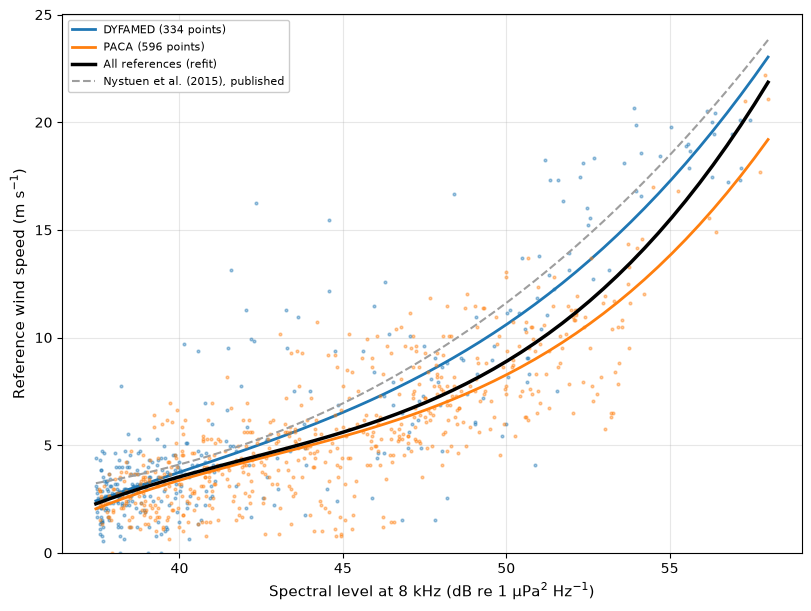

In [36]:
fig, ax = argopal.plot_reference_fits(cal["park"])

Here DYFAMED's curve is close to the published one and PACA's lower: the
two buoys disagree about the float-wind relationship, and the pooled
refit lies between them.

**Wind footprints instead of a distance.**  Near the coast, the wind a
few tens of kilometres from a buoy can differ from the buoy's.  With a
reanalysis of the 10 m wind over the float's area and period (e.g. ERA5
`u10`/`v10`), each measurement can be matched to the buoy whose wind
footprint (where the reanalysis wind varies as at the buoy, R ≥ 0.9)
covers it, instead of the closest buoy within 40 km.  No reanalysis comes
with these examples; with one:

```python
result = argopal.process_float(
    7902280,
    reference="data/reference_winds_2026.csv",
    footprints="era5_u10_v10_2026.nc",
    footprint_min_r=0.9,
)
argopal.plot_reference_map(result["park"], footprints=result["footprints"])
```

**Other table layouts.**

- Column names are recognised from common aliases (`time`, `ff`, `u10`,
  `lat`, `lon`, `station`, `buoy_name`, `sigma`, ...); see
  `argopal.read_reference`.
- A single fixed buoy whose table has no position columns:
  `argopal.collocate_reference(park, "buoy.csv", latitude=43.36, longitude=7.84)`.
- Moving references (ships, drifters): positions are read for every value.
- A dict collocates several sources separately, each under its own name:
  `reference={"dyfamed": "dyfamed.csv", "paca": "paca.csv"}`, with
  `fit_reference="paca"` to choose the one used for refitting.

## 8. Ship noise with AIS (optional)

Ship noise can dominate the 8 kHz band up to ~20 km away.  Given AIS vessel
positions for the float's area and period, measurements with a vessel within
20 km and ±30 min are flagged (`ships_nearby`, `ship_flag`).  With a
reference buoy as well, measurements whose refitted wind also deviates from
the buoy by more than the RMSE are marked `ship_contaminated`
(`ais_action="remove"` blanks only those).

No AIS data cover 7902280's 2026 track here, so this cell is not run.  AIS
can be a table (`datetime`, `mmsi`, `latitude`, `longitude`), decoded CSV
files, or raw NMEA files with tag-block receiver times (needs
`pip install argopal[ais]`):

```python
res = argopal.process_float(
    7902280,
    ais="AIS/messages-*.gz",          # or a DataFrame / CSV files
    reference="reference_winds.csv",
    ais_action="remove",
)
fig, axes = argopal.plot_ais(res["park"])
```

## 9. Export

Any table, or any set of tables, at any stage, as CSV or NetCDF:

In [37]:
argopal.export(cal, "output/wmo7902280", format="csv")

['output/wmo7902280_park.csv',
 'output/wmo7902280_pal_raw.csv',
 'output/wmo7902280_park_samples.csv',
 'output/wmo7902280_profiles.csv',
 'output/wmo7902280_ts_profiles.csv',
 'output/wmo7902280_wind_fits.csv',
 'output/wmo7902280_wind_skill.csv',
 'output/wmo7902280_wind_uncertainty.csv',
 'output/wmo7902280_beta.csv',
 'output/wmo7902280_positions.csv']

In [38]:
files = argopal.export(cal, "output/wmo7902280.nc", format="netcdf")
back = argopal.read_export(files[0])
list(back), back["park"].shape

(['park',
  'pal_raw',
  'park_samples',
  'profiles',
  'ts_profiles',
  'wind_fits',
  'wind_skill',
  'wind_uncertainty',
  'beta',
  'positions'],
 (72136, 71))

In [39]:
argopal.export(pal, "output/pal_step_by_step.csv")   # a single intermediate table

['output/pal_step_by_step.csv']